# Batería · Nivel 1 (ADTOF Frame RNN): datos, análisis y evaluación

**Objetivo:** evaluar el modelo preentrenado de ADTOF sobre una mezcla de tres datasets (MDB-Drums, ENST-Drums y E-GMD) y dejar lista la división de entrenamiento y prueba que usará el nivel 2.

**Carpetas del proyecto:**

```
proyecto/
├── datasets/     MDBDrums/, ENST/ (ya descargados) y EGMD/ (lo baja la sección 3)
├── models/       adtof_frame_rnn_pytorch_weights.pth
└── notebooks/    este notebook
```

**Pasos:**

1. Configuración
2. Modelo del nivel 1
3. Descarga de un subconjunto de E-GMD
4. Carga de datasets y mapeo de etiquetas
5. Análisis exploratorio
6. División entrenamiento / prueba
7. Pre-proceso y detección de picos
8. Evaluación del nivel 1
9. Escucha del MIDI resultante
10. Nivel 2: ajuste fino con cabeza de velocity **(VERSION 2: agregado al índice)**

## Decisiones registradas

| Tema | Decisión | Por qué |
|---|---|---|
| Ajustes al modelo | `eps` de BatchNorm = 1e-3, Dropout2d(0.3) y entrada de la GRU calculada | Igualar ADTOF-pytorch; solo `eps` cambia la inferencia y se mide en 7.1 |
| E-GMD: qué bajar | Las 819 secuencias de entrenamiento en 2 kits cada una, rotando los 43 kits; validación y prueba en 1 kit | El dataset repite cada interpretación en los 43 kits; así se cubren todos los ritmos y todos los kits sin la redundancia |
| E-GMD: recorte | 20 s por grabación de entrenamiento, con inicio fijo por archivo; validación y prueba completas | El modelo se entrena con ventanas de 4 s y un groove repite su patrón; la evaluación debe ser comparable con trabajos publicados |
| E-GMD: formato | FLAC mono de 16 bits | El modelo usa mono; 16 bits sobran para un espectrograma logarítmico; FLAC no pierde calidad |
| E-GMD: descarga | `RemoteZip` sobre el ZIP oficial, sin guardarlo | Lee solo el índice y los archivos elegidos; el ZIP de 90 GB nunca toca el disco |
| Meta de espacio | 3 a 4 GB para E-GMD | Límite de almacenamiento local; la sección 3 estima el tamaño antes de bajar |
| División de MDB y ENST | 30 % a prueba, por canción (MDB) y por baterista (ENST) | Evita que el mismo kit o baterista quede en ambos lados |
| División de E-GMD | La partición oficial | Todos los kits están en todas las particiones por diseño; permite comparar con resultados publicados |
| Identificador de pista **(VERSION 2)** | `dataset/ruta`, único; se verifica con un `assert` | Antes las 76 pistas de ENST compartían un identificador y se mezclaban sus anotaciones |
| ENST disponible **(VERSION 2)** | 2 bateristas con audio (frases de solo batería del repo georgid); uno para entrenar y otro para probar | drummer_3 no tiene audio y las pistas minus-one no traen la batería |
| Validación del nivel 2 **(VERSION 2)** | Se elige el modelo y los umbrales con el promedio del F1 de cada dataset | Con el F1 micro, E-GMD (117 pistas completas) decidía casi solo |

**(VERSION 2)** Los cambios de esta versión están marcados con `(VERSION 2)` en comentarios y textos. Antes de correr: borrar o ignorar la carpeta vieja `cache_nivel2/` (ahora se usa `cache_nivel2_v2/`) y ejecutar *Restart Kernel + Run All*.

## 1. Configuración

Todas las constantes en un solo lugar.

- **`CLASES`:** las 5 salidas del modelo, en su orden.
- **`NOTA_GM`:** la nota MIDI con que se escribe cada clase.
- **`UMBRALES`:** probabilidad mínima para aceptar un golpe, por clase; son los valores de ADTOF.
- **`TOLERANCIA`:** distancia máxima entre un golpe predicho y uno anotado para contarlo como acierto (50 ms, el estándar).

Dependencias: `pip install librosa soundfile pretty_midi mir_eval huggingface_hub remotezip scipy pandas matplotlib`.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, soundfile as sf, pretty_midi, mir_eval
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.ndimage import uniform_filter1d, maximum_filter1d
from IPython.display import display, Audio

DATA_DIR = Path.cwd().parent / "datasets"          # carpeta del proyecto, un nivel arriba de notebooks/
RUTA_PESOS = Path.cwd().parent / "models" / "adtof_frame_rnn_pytorch_weights.pth"

SR, FPS = 44100, 100                                   # audio a 44.1 kHz, 100 cuadros por segundo
CLASES = ["BD", "SD", "TT", "HH", "CY"]                # orden de salida del modelo
NOMBRES = {"BD": "Bombo", "SD": "Caja", "TT": "Toms", "HH": "Hi-hat", "CY": "Platillos"}
NOTA_GM = {"BD": 36, "SD": 38, "TT": 47, "HH": 42, "CY": 49}
UMBRALES = {"BD": 0.22, "SD": 0.24, "TT": 0.32, "HH": 0.22, "CY": 0.30}
TOLERANCIA = 0.05                                      # segundos

## 2. Modelo del nivel 1

Es la misma arquitectura de tu notebook con tres ajustes para igualarla a ADTOF-pytorch:

| Ajuste | Antes | Ahora | Efecto |
|---|---|---|---|
| `eps` de BatchNorm | 1e-5 (valor por defecto de PyTorch) | 1e-3 (valor de Keras y de ADTOF-pytorch) | Cambia ligeramente las activaciones; se mide en la sección 7 |
| Dropout2d(0.3) después de cada bloque | No estaba | Agregado | Ninguno al evaluar (`eval()` lo apaga); necesario para entrenar el nivel 2 |
| Entrada de la primera GRU | 640 escrito a mano | Calculada a partir de las 84 bandas | Ninguno; evita errores si cambia el pre-proceso |

El Dropout se aplica fuera de los `Sequential`, así que los nombres de los pesos no cambian y el checkpoint carga igual.

**Cómo fluye un fragmento de audio por el modelo:**

1. Entra un espectrograma de forma (tiempo, 84 bandas).
2. Dos bloques convolucionales detectan patrones locales de cada golpe. Después de cada bloque, un max-pooling reduce la frecuencia a un tercio: 84 → 28 → 10.
3. Por cada cuadro de tiempo quedan 64 canales × 10 bandas = 640 valores.
4. Tres GRU bidireccionales leen la secuencia completa y aprenden el contexto rítmico.
5. Una capa lineal con sigmoide da 5 probabilidades por cuadro, una por clase.

In [2]:
def pool_same(x, k=3):
    # MaxPool (1, k) en frecuencia con padding 'same' de TensorFlow (rellena con -inf; el sobrante va a la derecha)
    f = x.shape[-1]
    total = max(math.ceil(f / k) * k - f, 0)
    x = F.pad(x, (total // 2, total - total // 2), value=float("-inf"))
    return F.max_pool2d(x, (1, k))

class FrameRNN(nn.Module):
    def __init__(self, n_bandas=84, filters=(32, 64), gru_units=60, n_classes=5):
        super().__init__()
        self.cnn_blocks = nn.ModuleList()
        c_in = 1
        for f in filters:
            self.cnn_blocks.append(nn.Sequential(
                nn.Conv2d(c_in, f, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(f, eps=1e-3),
                nn.Conv2d(f, f, 3, padding=1),    nn.ReLU(), nn.BatchNorm2d(f, eps=1e-3)))
            c_in = f
        self.dropout = nn.Dropout2d(0.3)
        bandas = n_bandas
        for _ in filters:
            bandas = math.ceil(bandas / 3)                  # 84 -> 28 -> 10
        entrada = filters[-1] * bandas                      # 64 x 10 = 640
        self.gru_layers = nn.ModuleList([
            nn.GRU(entrada, gru_units, batch_first=True, bidirectional=True),
            nn.GRU(2 * gru_units, gru_units, batch_first=True, bidirectional=True),
            nn.GRU(2 * gru_units, gru_units, batch_first=True, bidirectional=True)])
        self.output_layer = nn.Linear(2 * gru_units, n_classes)

    def forward(self, x):                                  # x: (B, T, 84)
        x = x.unsqueeze(1)                                 # (B, 1, T, 84)
        for blk in self.cnn_blocks:
            x = self.dropout(pool_same(blk(x)))
        x = x.permute(0, 2, 3, 1).reshape(x.shape[0], x.shape[2], -1)   # (B, T, 640)
        for g in self.gru_layers:
            x, _ = g(x)
        return torch.sigmoid(self.output_layer(x))         # (B, T, 5)

ckpt = torch.load(RUTA_PESOS, map_location="cpu")
model = FrameRNN()
model.load_state_dict(ckpt["model_weights"])
model.eval()
print("Pesos cargados desde", RUTA_PESOS)

Pesos cargados desde c:\Users\HP\Documents\GitHub\Track2Sheet\models\adtof_frame_rnn_pytorch_weights.pth


## 3. Descarga de un subconjunto de E-GMD

E-GMD completo pesa 90 GB comprimido. Esta sección baja solo un subconjunto de 3 a 4 GB, en cuatro pasos:

1. **Metadatos y MIDI** del espejo de Hugging Face: el CSV y un ZIP de 103 MB con todos los MIDI. Se extraen los MIDI elegidos y se borra el ZIP.
2. **Elegir qué grabaciones bajar.** Cada secuencia se grabó en los 43 kits. Se toma cada secuencia en pocos kits, rotando para que los 43 queden cubiertos por igual.
3. **Estimar el tamaño** antes de bajar nada, con las duraciones del CSV.
4. **Bajar el audio** con `RemoteZip`: lee el ZIP oficial directamente del servidor y descarga solo los archivos elegidos. Cada archivo pasa por memoria, se recorta, se convierte a FLAC mono de 16 bits y se guarda. El ZIP nunca se guarda en disco.

La descarga se puede detener y retomar: los archivos ya guardados se saltan.

**(VERSION 2)** Si el CSV, los MIDI y el audio ya están en `datasets/EGMD/`, esta sección no descarga nada ni necesita internet.

Si ya habías bajado E-GMD dentro de `notebooks/datasets/`, esa carpeta se puede borrar.

In [3]:
import io, zlib, time
from huggingface_hub import list_repo_files, hf_hub_download
from remotezip import RemoteZip
import zipfile

EGMD_DIR = DATA_DIR / "EGMD"
EGMD_HF = "yalishanda/e-gmd-v1.0.0-midi"
# ZIP oficial: enlace de descarga de https://magenta.withgoogle.com/datasets/e-gmd (Google Cloud Storage).
# Si falla, usar el espejo de Zenodo: "https://zenodo.org/records/4300943/files/e-gmd-v1.0.0.zip"
URL_ZIP_AUDIO = "https://storage.googleapis.com/magentadata/datasets/e-gmd/v1.0.0/e-gmd-v1.0.0.zip"

def indice_por_sufijo(nombres):
    # Permite encontrar 'drummer1/x.wav' aunque en el ZIP esté como 'e-gmd-v1.0.0/drummer1/x.wav'
    indice = {}
    for n in nombres:
        partes = n.split("/")
        for i in range(len(partes)):
            indice.setdefault("/".join(partes[i:]), n)
    return indice

# 1) Metadatos
# (VERSION 2) Si el CSV ya está en disco se usa directamente, sin consultar Hugging Face: el notebook corre sin internet
ruta_csv = EGMD_DIR / "e-gmd-v1.0.0.csv"
if not ruta_csv.exists():
    archivos_hf = list_repo_files(EGMD_HF, repo_type="dataset")
    ruta_csv = hf_hub_download(EGMD_HF, next(f for f in archivos_hf if f.endswith(".csv")), repo_type="dataset", local_dir=EGMD_DIR)
meta_egmd = pd.read_csv(ruta_csv)
print(meta_egmd.groupby("split").agg(grabaciones=("id", "size"), horas=("duration", lambda d: round(d.sum() / 3600, 1))))
print("Kits por secuencia (debe ser ~43):", meta_egmd.groupby("id")["kit_name"].nunique().median())

e-gmd-v1.0.0.csv: 0.00B [00:00, ?B/s]

            grabaciones  horas
split                         
test               5289   50.9
train             35217  341.4
validation         5031   52.2
Kits por secuencia (debe ser ~43): 43.0


In [4]:
# 2) Selección: cada secuencia en 'k' kits, rotando para cubrir los 43 por igual
KITS = sorted(meta_egmd["kit_name"].unique())

def submuestra(split, k):
    df = meta_egmd[meta_egmd["split"] == split]
    partes = []
    for i, (_, g) in enumerate(df.groupby("id")):
        elegidos = {KITS[(i * k + j) % len(KITS)] for j in range(k)}
        partes.append(g[g["kit_name"].isin(elegidos)])
    return pd.concat(partes, ignore_index=True)

# 3) Estimación de tamaño: 0.30 GB/h sale de 132 GB / 444.5 h del dataset oficial; FLAC ~0.5 (ajustar tras medir)
GB_POR_HORA, FACTOR_FLAC = 0.30, 0.5
evaluacion = pd.concat([submuestra("validation", 1), submuestra("test", 1)])
gb_evaluacion = evaluacion["duration"].sum() / 3600 * GB_POR_HORA * FACTOR_FLAC

filas = []
for k in (1, 2, 3):
    entrenamiento = submuestra("train", k)
    for recorte in (None, 30, 20, 15):
        dur = entrenamiento["duration"] if recorte is None else entrenamiento["duration"].clip(upper=recorte)
        horas = dur.sum() / 3600
        filas.append({"kits/secuencia": k, "recorte (s)": recorte or "completo", "archivos": len(entrenamiento),
                      "horas entrenamiento": round(horas, 1),
                      "GB total estimado": round(horas * GB_POR_HORA * FACTOR_FLAC + gb_evaluacion, 2)})
display(pd.DataFrame(filas))

,kits/secuencia,recorte (s),archivos,horas entrenamiento,GB total estimado
0,1,completo,819,7.9,1.55
1,1,30,819,2.4,0.72
2,1,20,819,1.8,0.64
3,1,15,819,1.5,0.59
4,2,completo,1638,15.9,2.74
5,2,30,1638,4.8,1.08
6,2,20,1638,3.7,0.91
7,2,15,1638,3.0,0.82
8,3,completo,2457,23.8,3.93
9,3,30,2457,7.2,1.45


In [5]:
# Elegir según la tabla: la combinación con más kits por secuencia que quede en 3-4 GB
K, RECORTE_S = 2, 20

sub = pd.concat([submuestra("train", K), submuestra("validation", 1), submuestra("test", 1)], ignore_index=True)

# Inicio del recorte: fijo por archivo (depende de su nombre), así se reconstruye siempre igual
fraccion = sub["audio_filename"].map(lambda n: zlib.crc32(n.encode()) / 2**32)
es_train = sub["split"] == "train"
sub["inicio"] = np.where(es_train, (fraccion * (sub["duration"] - RECORTE_S).clip(lower=0)).round(2), 0.0)
sub["fin"] = np.where(es_train, sub["inicio"] + sub["duration"].clip(upper=RECORTE_S), sub["duration"])
sub.to_csv(EGMD_DIR / "subconjunto_egmd.csv", index=False)
display(sub.groupby("split").agg(archivos=("id", "size"), kits=("kit_name", "nunique"), secuencias=("id", "nunique"),
                                 horas=("fin", lambda f: round((f - sub.loc[f.index, "inicio"]).sum() / 3600, 2))))

# MIDI: se extraen los elegidos y se borra el ZIP de 103 MB
# (VERSION 2) El ZIP solo se baja si falta algún MIDI; antes se bajaba en cada ejecución porque se borra al final
faltan_midi = [r for r in sub["midi_filename"] if not (EGMD_DIR / "midi" / r).exists()]
if faltan_midi:
    archivos_hf = list_repo_files(EGMD_HF, repo_type="dataset")
    zip_midi = Path(hf_hub_download(EGMD_HF, next(f for f in archivos_hf if f.endswith(".zip")), repo_type="dataset", local_dir=EGMD_DIR))
    with zipfile.ZipFile(zip_midi) as z:
        indice = indice_por_sufijo(z.namelist())
        for ruta in faltan_midi:
            salida = EGMD_DIR / "midi" / ruta
            salida.parent.mkdir(parents=True, exist_ok=True)
            salida.write_bytes(z.read(indice[ruta]))
    zip_midi.unlink()
else:
    print("(VERSION 2) Todos los MIDI ya estaban; no se descarga el ZIP")
print("MIDI extraídos:", sum(1 for _ in (EGMD_DIR / "midi").rglob("*.mid*")))

,archivos,kits,secuencias,horas
split,,,,
test,123,43,123,1.18
train,1638,43,819,3.68
validation,117,43,117,1.21


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


e-gmd-v1.0.0-midi.zip:   0%|          | 0.00/107M [00:00<?, ?B/s]

MIDI extraídos: 1878


In [6]:
# 4) Audio: solo los archivos elegidos, recortados y en FLAC, con progreso
def bajar_audio(sub, url=URL_ZIP_AUDIO, cada=10):
    pendientes = [f for f in sub.itertuples() if not (EGMD_DIR / "audio" / f.audio_filename).with_suffix(".flac").exists()]
    print(f"{len(sub) - len(pendientes)} ya estaban; faltan {len(pendientes)}")
    if not pendientes:
        return
    with RemoteZip(url) as rz:                                   # baja solo el índice del ZIP
        indice = indice_por_sufijo(rz.namelist())
        total_mb = sum(rz.getinfo(indice[f.audio_filename]).compress_size for f in pendientes) / 1e6
        bajado_mb, guardado_mb, t0 = 0.0, 0.0, time.time()
        for n, f in enumerate(pendientes, 1):
            miembro = indice[f.audio_filename]
            datos, sr = sf.read(io.BytesIO(rz.read(miembro)), always_2d=True)    # descarga en memoria
            segmento = datos.mean(axis=1)[int(f.inicio * sr): int(f.fin * sr)]   # mono + recorte
            salida = (EGMD_DIR / "audio" / f.audio_filename).with_suffix(".flac")
            salida.parent.mkdir(parents=True, exist_ok=True)
            sf.write(salida, segmento, sr, subtype="PCM_16")
            bajado_mb += rz.getinfo(miembro).compress_size / 1e6
            guardado_mb += salida.stat().st_size / 1e6
            if n % cada == 0 or n == len(pendientes):
                seg = time.time() - t0
                restante = (total_mb - bajado_mb) / (bajado_mb / seg) / 60 if bajado_mb else float("nan")
                print(f"\r{n}/{len(pendientes)} archivos | bajado {bajado_mb:,.0f} de {total_mb:,.0f} MB "
                      f"| en disco {guardado_mb:,.0f} MB | {bajado_mb / seg:.1f} MB/s | faltan ~{restante:.0f} min", end="")
    print()

# Prueba primero con 10 archivos para medir velocidad y el factor real de FLAC; después, con todos.
bajar_audio(sub.head(10))

0 ya estaban; faltan 10
10/10 archivos | bajado 61 de 61 MB | en disco 4 MB | 1.1 MB/s | faltan ~0 min


In [7]:
bajar_audio(sub)

10 ya estaban; faltan 1868
1868/1868 archivos | bajado 3,911 de 3,911 MB | en disco 761 MB | 1.0 MB/s | faltan ~0 minn


## 4. Carga de datasets y mapeo de etiquetas

Cada dataset nombra las piezas de la batería a su manera. Todo se lleva a **dos tablas comunes**:

- **`pistas`:** una fila por archivo de audio. Columnas: `dataset`, `pista`, `audio`, `grupo` (para la división de la sección 6) y metadatos.
- **`onsets`:** una fila por golpe anotado. Columnas: `dataset`, `pista`, `tiempo` (s), `etiqueta` (la original), `clase` (una de las 5) y `velocity` (solo E-GMD).

**Mapeo de etiquetas a las 5 clases del modelo:**

| Clase | MDB | ENST | E-GMD (nota MIDI) |
|---|---|---|---|
| BD · Bombo | KD | bd | 35, 36 |
| SD · Caja (incluye rimshot y cross-stick) | SD | sd, rs, cs | 37, 38, 40 |
| TT · Toms | TT | lmt, mt, lt, ht, lft… | 41, 43, 45, 47, 48, 50, 58 |
| HH · Hi-hat | HH | chh, ohh | 22, 26, 42, 44, 46 |
| CY · Platillos (crash y ride juntos, como en ADTOF) | CY | cr, ch, rc, spl, c1… | 49, 51, 52, 53, 55, 57, 59 |
| Se ignora | OT | cb (cencerro) | resto |

**Qué información trae cada dataset:**

| | MDB-Drums | ENST-Drums | E-GMD |
|---|---|---|---|
| Tipo de grabación | Canciones reales producidas | 3 bateristas, cada uno con su kit; **(VERSION 2)** aquí solo 2 tienen audio | Kit electrónico Roland TD-17, 43 sonidos |
| Formato de anotación | Texto: tiempo y etiqueta | Texto: tiempo y etiqueta | MIDI |
| Velocity | No | No | Sí |
| Offset | No | No | Sí (no se usa en batería) |
| Metadatos | — | Baterista | Kit, estilo, bpm, partición oficial |
| En este proyecto | 23 pistas completas | **(VERSION 2)** 76 frases de solo batería (~16 s cada una) del repo georgid; no son las pistas minus-one | Subconjunto de la sección 3: entrenamiento recortado a 20 s |

In [38]:
MAPA_MDB = {"KD": "BD", "SD": "SD", "TT": "TT", "HH": "HH", "CY": "CY"}

MAPA_EGMD = {}
for clase, notas in {"BD": [35, 36], "SD": [37, 38, 40], "TT": [41, 43, 45, 47, 48, 50, 58],
                     "HH": [22, 26, 42, 44, 46], "CY": [49, 51, 52, 53, 55, 57, 59]}.items():
    for n in notas:
        MAPA_EGMD[n] = clase

def clase_enst(etiqueta):
    e = etiqueta.lower()
    if e.startswith("bd"):                      return "BD"
    if e.startswith(("sd", "rs", "cs")):        return "SD"
    if e.startswith(("chh", "ohh")):            return "HH"   # antes que 'ch' (china)
    if e.startswith(("lmt", "mt", "lt", "ht", "lft")): return "TT"
    if e.startswith(("cr", "ch", "rc", "spl", "c1", "c2", "c3", "c4", "c5")): return "CY"
    return None                                  # cb y otras

def leer_txt(ruta):
    # Anotación en texto: cada línea es 'tiempo etiqueta'
    tabla = pd.read_csv(ruta, sep=r"\s+", header=None, usecols=[0, 1], names=["tiempo", "etiqueta"])
    return tabla

In [44]:
pistas, onsets = [], []

# --- MDB: audio solo batería + anotaciones por clase ---
raiz = DATA_DIR / "MDBDrums" / "MDB Drums"
for ann in sorted((raiz / "annotations" / "class").glob("*_class.txt")):
    nombre = ann.stem.replace("_class", "")
    audio = raiz / "audio" / "drum_only" / f"{nombre}_Drum.wav"
    if not audio.exists():
        print("Sin audio:", nombre)
        continue
    pistas.append({"dataset": "MDB", "pista": f"MDB/{nombre}", "audio": audio, "grupo": nombre})
    t = leer_txt(ann).assign(dataset="MDB", pista=f"MDB/{nombre}")
    t["clase"] = t["etiqueta"].map(MAPA_MDB)
    onsets.append(t)

# --- ENST: drummer_X/ tiene juntos el .wav y el .txt de cada pista; drummer_X/accompaniment/ el acompañamiento ---
# (VERSION 2) Se quitó SOLO_CON_ACOMPANAMIENTO: en este repo las pistas minus-one no traen el audio de batería,
#             así que con True quedaban 0 pistas. Se usan las frases de solo batería de drummer_1 y drummer_2.
sin_audio = []
for carpeta in sorted((DATA_DIR / "ENST").glob("drummer_*")):
    for ann in sorted(carpeta.glob("*.txt")):
        if ".onsets." in ann.name:      # (VERSION 2) salidas de detectores de onsets, no son anotaciones
            continue
        audio = carpeta / f"{ann.stem}.wav"
        acomp = carpeta / "accompaniment" / f"{ann.stem}.wav"
        if not audio.exists():
            sin_audio.append(ann.name)
            continue
        # (VERSION 2) Antes: pid = "ENST/" + Path(fila.audio_filename)... usaba 'fila', la variable del bucle de E-GMD
        #             que quedaba de una ejecución anterior: las 76 pistas ENST recibían el mismo identificador.
        pid = f"ENST/{carpeta.name}/{ann.stem}"      # p. ej. ENST/drummer_1/036_phrase_disco_simple_slow_sticks
        pistas.append({"dataset": "ENST", "pista": pid, "audio": audio, "grupo": carpeta.name,
                       "acompanamiento": acomp if acomp.exists() else None})
        t = leer_txt(ann).assign(dataset="ENST", pista=pid)
        t["clase"] = t["etiqueta"].map(clase_enst)
        onsets.append(t)
print(f"ENST: {sum(p['dataset'] == 'ENST' for p in pistas)} pistas cargadas; {len(sin_audio)} anotaciones sin .wav")

# --- E-GMD: subconjunto descargado en la sección 3 (audio recortado en FLAC + MIDI completo) ---
raiz = DATA_DIR / "EGMD"
meta = pd.read_csv(raiz / "subconjunto_egmd.csv")
for fila in meta.itertuples():
    audio, midi = (raiz / "audio" / fila.audio_filename).with_suffix(".flac"), raiz / "midi" / fila.midi_filename
    if not (audio.exists() and midi.exists()):
        continue
    pid = "E-GMD/" + Path(fila.audio_filename).with_suffix("").as_posix()
    pistas.append({"dataset": "E-GMD", "pista": pid, "audio": audio, "grupo": fila.kit_name,
                   "kit": fila.kit_name, "estilo": fila.style, "bpm": fila.bpm, "split_oficial": fila.split})
    notas = [(n.start, n.pitch, n.velocity) for inst in pretty_midi.PrettyMIDI(str(midi)).instruments for n in inst.notes]
    t = pd.DataFrame(notas, columns=["tiempo", "etiqueta", "velocity"]).assign(dataset="E-GMD", pista=pid)
    t = t[(t["tiempo"] >= fila.inicio) & (t["tiempo"] < fila.fin)].copy()
    t["tiempo"] -= fila.inicio                                  # tiempos relativos al recorte
    t["clase"] = t["etiqueta"].map(MAPA_EGMD)
    onsets.append(t)

pistas = pd.DataFrame(pistas)
# (VERSION 2) Cada pista debe tener un identificador único; si no, sus anotaciones se mezclan en 'onsets'
assert pistas["pista"].is_unique, pistas.loc[pistas["pista"].duplicated(keep=False), ["dataset", "pista"]]
pistas["duracion"] = [sf.info(str(a)).duration for a in pistas["audio"]]
onsets = pd.concat(onsets, ignore_index=True).sort_values(["pista", "tiempo"], ignore_index=True)
display(pistas.groupby("dataset").agg(pistas=("pista", "size"), minutos=("duracion", lambda d: round(d.sum() / 60, 1))))

ENST: 76 pistas cargadas; 59 anotaciones sin .wav


,pistas,minutos
dataset,,
E-GMD,1878,364.5
ENST,76,20.8
MDB,23,21.8


In [ ]:
# (VERSION 2) Verificación rápida: identificadores únicos y pistas por baterista de ENST.
#             Antes esta celda imprimía 'pesos' y 'train_ids', que se definen hasta el nivel 2.
print("Pistas con identificador repetido:", pistas["pista"].duplicated().sum())
display(pistas[pistas["dataset"] == "ENST"].groupby("grupo").size().rename("pistas ENST"))

## 5. Análisis exploratorio

Cada tabla responde una pregunta que afecta al modelo:

| Pregunta | Por qué importa |
|---|---|
| ¿Qué etiquetas quedaron fuera de las 5 clases? | Verifica el mapeo; esos golpes no se evalúan |
| ¿Cuántos golpes hay por clase? | Si una clase es escasa (toms), su F1 es poco confiable y conviene reportar F1 macro |
| ¿Cuántos golpes por segundo? | Densidad rítmica de cada dataset |
| ¿Qué tan seguido suenan dos piezas a la vez? | Mide qué tan multietiqueta es el problema |
| ¿Cuántos golpes de la misma clase caen a menos de 20 ms? | La detección de picos junta golpes a menos de 20 ms: esos casos se pierden siempre |
| ¿Cómo se distribuye la velocity? | Solo E-GMD; servirá para la cabeza de velocity del nivel 2 |

Etiquetas fuera de las 5 clases:


golpes
dataset etiqueta        
E-GMD   39            74
        54          3027
        56            59
ENST    cb            76
MDB     OT            70

clase,BD,SD,TT,HH,CY
dataset,,,,,
E-GMD,35177,57483,17965,50360,19244
ENST,1906,2194,604,2093,1047
MDB,1539,2654,90,2639,1002


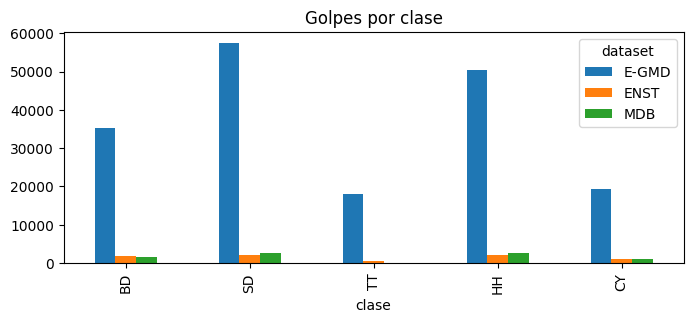

Golpes por segundo: {'E-GMD': 8.24, 'ENST': 6.29, 'MDB': 6.05}


In [46]:
# Etiquetas que no entran en las 5 clases
fuera = onsets[onsets["clase"].isna()].groupby(["dataset", "etiqueta"]).size().rename("golpes")
print("Etiquetas fuera de las 5 clases:")
display(fuera.to_frame())

validos = onsets.dropna(subset=["clase"])

# Golpes por clase y por dataset
conteo = pd.crosstab(validos["dataset"], validos["clase"])[CLASES]
display(conteo)
conteo.T.plot.bar(figsize=(8, 3), title="Golpes por clase")
plt.show()

# Densidad: golpes por segundo
densidad = validos.groupby("dataset").size() / pistas.groupby("dataset")["duracion"].sum()
print("Golpes por segundo:", densidad.round(2).to_dict())

In [47]:
def distancia_minima(t, otros):
    # Para cada tiempo de 't', distancia al tiempo más cercano de 'otros' (ambos ordenados)
    if len(otros) == 0:
        return np.full(len(t), np.inf)
    i = np.clip(np.searchsorted(otros, t), 1, len(otros) - 1)
    return np.minimum(np.abs(t - otros[i - 1]), np.abs(t - otros[i]))

filas = []
for (dataset, pista), g in validos.groupby(["dataset", "pista"]):
    for c in CLASES:
        t = np.sort(g.loc[g["clase"] == c, "tiempo"].to_numpy())
        otros = np.sort(g.loc[g["clase"] != c, "tiempo"].to_numpy())
        filas.append({"dataset": dataset, "clase": c, "golpes": len(t),
                      "simultaneos": int((distancia_minima(t, otros) <= 0.010).sum()),
                      "menos_de_20ms": int((np.diff(t) < 0.020).sum())})

simult = pd.DataFrame(filas).groupby(["dataset", "clase"]).sum()
simult["% simultáneos"] = (100 * simult["simultaneos"] / simult["golpes"]).round(1)
display(simult)

# Velocity (solo E-GMD)
display(validos[validos["dataset"] == "E-GMD"].groupby("clase")["velocity"].describe().reindex(CLASES).round(1))

golpes  simultaneos  menos_de_20ms  % simultáneos
dataset clase                                                   
E-GMD   BD      35177        13605              9           38.7
        CY      19244         8368            145           43.5
        HH      50360        14738            752           29.3
        SD      57483        13616            466           23.7
        TT      17965         3608            492           20.1
ENST    BD       1906         1880           1578           98.6
        CY       1047         1007            628           96.2
        HH       2093         2077           1844           99.2
        SD       2194         2122           1890           96.7
        TT        604          592            269           98.0
MDB     BD       1539          717              0           46.6
        CY       1002          524              1           52.3
        HH       2639          976              2           37.0
        SD       2654          643              2           24.2
        TT         90           16              0           17.8

,count,mean,std,min,25%,50%,75%,max
clase,,,,,,,,
BD,35177.0,56.9,31.3,6.0,36.0,51.0,69.0,127.0
SD,57483.0,70.2,40.2,4.0,36.0,62.0,112.0,127.0
TT,17965.0,92.1,27.4,7.0,71.0,93.0,118.0,127.0
HH,50360.0,68.7,32.5,4.0,43.0,65.0,91.0,127.0
CY,19244.0,75.2,31.3,4.0,51.0,70.0,100.0,127.0


## 6. División entrenamiento / prueba

La división se fija ahora para que el nivel 1 y el nivel 2 se evalúen sobre **las mismas pistas de prueba**.

Tres reglas:

- **Estratificada por dataset:** MDB y ENST aportan la misma proporción (30 %) de su contenido a prueba, así ninguno domina el resultado.
- **Por grupo, no por pista:** todas las pistas de un mismo grupo van al mismo lado. Si el mismo kit o baterista estuviera en ambos lados, el nivel 2 memorizaría su sonido y la prueba saldría inflada.
    - MDB: cada canción es su propio grupo.
    - ENST: el grupo es el baterista, porque cada uno toca su propio kit. **(VERSION 2)** Solo hay 2 bateristas con audio, así que el 30 % redondea a uno: un baterista completo va a prueba y el otro a entrenamiento.
- **E-GMD usa su partición oficial** (entrenamiento, validación, prueba). Cada secuencia se grabó en los 43 kits, así que no se puede dividir por kit; la partición oficial separa interpretaciones y es la que usan los trabajos publicados.

El resultado se guarda en `division_bateria.csv`.

In [48]:
FRACCION_PRUEBA, SEMILLA = 0.3, 0

rng = np.random.default_rng(SEMILLA)
pistas["split"] = "train"
# E-GMD conserva su partición oficial
es_egmd = pistas["dataset"] == "E-GMD"
pistas.loc[es_egmd, "split"] = pistas.loc[es_egmd, "split_oficial"].replace({"validation": "val"})
for dataset, g in pistas[~es_egmd].groupby("dataset"):
    grupos = g["grupo"].unique()
    rng.shuffle(grupos)
    n_prueba = max(1, round(FRACCION_PRUEBA * len(grupos)))
    pistas.loc[g.index[g["grupo"].isin(grupos[:n_prueba])], "split"] = "test"

display(pd.crosstab(pistas["dataset"], pistas["split"], values=pistas["duracion"] / 60,
                    aggfunc="sum").round(1).rename_axis(columns="minutos"))
pistas[["dataset", "pista", "grupo", "split"]].to_csv("division_bateria.csv", index=False)

minutos,test,train,val
dataset,,,
E-GMD,71.0,220.6,72.8
ENST,6.5,14.3,NaN
MDB,7.9,13.9,NaN


## 7. Pre-proceso y detección de picos

Los pesos solo funcionan si el espectrograma se calcula exactamente como en el entrenamiento de ADTOF.

**Pre-proceso:**

1. Audio mono a 44.1 kHz.
2. STFT con ventana de 2048 muestras y salto de 441, es decir 100 cuadros por segundo (un cuadro cada 10 ms).
3. Se agrupan las frecuencias en 84 bandas: 12 por octava entre 20 Hz y 20 kHz, con filtros triangulares. Así las bandas son finas en graves y anchas en agudos, como el oído.
4. Compresión logarítmica: `log10(1 + x)`.

**Detección de picos.** El modelo da una curva de probabilidad por clase; hay que convertirla en instantes de golpe. Un cuadro es un golpe si cumple tres condiciones:

1. Supera el umbral de su clase.
2. Supera el promedio de los 100 ms anteriores. Esto descarta zonas donde la curva queda alta sin que haya un ataque nuevo.
3. Es el máximo en una ventana de 20 ms antes y 10 ms después.

Si dos golpes quedan a menos de 20 ms, se conserva el más alto.

**(VERSION 2)** Esta detección reproduce la de madmom, que es la que usó ADTOF: el umbral se aplica a la activación. La reimplementación de ADTOF-pytorch aplica el umbral a la activación menos su promedio, así que sus golpes pueden diferir un poco.

In [49]:
def banco_de_filtros(n_fft=2048, sr=SR, bandas_por_octava=12, fmin=20.0, fmax=20000.0):
    freqs_fft = np.fft.rfftfreq(n_fft, 1 / sr)[: n_fft // 2]
    # Frecuencias centrales: 12 por octava, llevadas al bin de FFT más cercano y sin repetir
    centrales = fmin * 2 ** (np.arange(200) / bandas_por_octava)
    centrales = centrales[centrales <= fmax]
    bins = np.unique([np.argmin(np.abs(freqs_fft - f)) for f in centrales])
    filtros = np.zeros((len(bins) - 2, n_fft // 2), dtype=np.float32)
    for i in range(len(bins) - 2):
        izq, centro, der = bins[i], bins[i + 1], bins[i + 2]
        filtros[i, izq:centro + 1] = np.linspace(0, 1, centro - izq + 1)   # subida
        filtros[i, centro:der] = np.linspace(1, 0, der - centro + 1)[:-1]  # bajada
        filtros[i] /= filtros[i].sum()                                     # cada filtro suma 1
    return filtros

FILTROS = banco_de_filtros()
print("Bandas:", FILTROS.shape[0])          # deben ser 84

def espectrograma(y):
    stft = librosa.stft(y, n_fft=2048, hop_length=441, window=np.hanning(2048), center=True, pad_mode="constant")
    magnitud = np.abs(stft)[:1024]
    return np.log10(1 + FILTROS @ magnitud).T.astype(np.float32)          # (tiempo, 84)

@torch.no_grad()
def activaciones(y, modelo=None):
    modelo = model if modelo is None else modelo
    x = torch.from_numpy(espectrograma(y))[None]
    return modelo(x)[0].numpy()                                            # (tiempo, 5)

def detectar_picos(curva, umbral):
    candidatos = curva * (curva >= uniform_filter1d(curva, 12, mode="constant", origin=4))  # promedio móvil
    candidatos = candidatos * (candidatos >= umbral)
    es_maximo = candidatos == maximum_filter1d(candidatos, 4, mode="constant", origin=0)
    cuadros = np.flatnonzero(es_maximo & (candidatos > 0))
    finales, previo = [], None
    for c in cuadros:                                                      # combinar a menos de 20 ms
        if previo is not None and c - previo <= 2:
            if curva[c] > curva[finales[-1]]:
                finales[-1] = c                                            # se queda el más alto
        else:
            finales.append(c)
        previo = c
    return np.array(finales) / FPS

def transcribir(y, modelo=None):
    act = activaciones(y, modelo)
    golpes = {c: detectar_picos(act[:, i], UMBRALES[c]) for i, c in enumerate(CLASES)}
    return golpes, act

Bandas: 84


### 7.1 ¿Cuánto cambia el ajuste de `eps`?

Se compara el modelo con `eps = 1e-5` (tu versión original) contra `eps = 1e-3` (ADTOF) en las primeras pistas de prueba. Se reportan la diferencia máxima entre activaciones y cuántos golpes detectados cambian.

**(VERSION 2) Conclusión:** la diferencia máxima de activación llega a ~0.8 y cerca de la mitad de los golpes cambia. El `eps` sí importa; se usa 1e-3, el mismo valor de `adtof_pytorch/model.py`.

In [50]:
modelo_original = FrameRNN()
modelo_original.load_state_dict(ckpt["model_weights"])
for m in modelo_original.modules():
    if isinstance(m, nn.BatchNorm2d):
        m.eps = 1e-5
modelo_original.eval()

filas = []
for p in pistas[pistas["split"] == "test"].groupby("dataset").head(2).itertuples():
    y, _ = librosa.load(str(p.audio), sr=SR, mono=True)
    g_adtof, a_adtof = transcribir(y)
    g_orig, a_orig = transcribir(y, modelo_original)
    n_adtof = sum(len(v) for v in g_adtof.values())
    n_iguales = sum(len(mir_eval.util.match_events(g_adtof[c], g_orig[c], 0.005)) for c in CLASES
                    if len(g_adtof[c]) and len(g_orig[c]))
    filas.append({"pista": p.pista, "dif. máx. activación": np.abs(a_adtof - a_orig).max(),
                  "golpes (eps 1e-3)": n_adtof, "golpes iguales": n_iguales})
display(pd.DataFrame(filas).round(4))

,pista,dif. máx. activación,golpes (eps 1e-3),golpes iguales
0,MDB/MusicDelta_BebopJazz,0.7872,738,465
1,MDB/MusicDelta_CoolJazz,0.8256,453,131
2,ENST/drummer9/session1/7_rock_100_beat_4-4_4,0.8413,59,8
3,ENST/drummer9/session1/7_rock_100_beat_4-4_4,0.8122,61,11
4,E-GMD/drummer1/eval_session/1_funk-groove1_138...,0.7551,262,118
5,E-GMD/drummer1/eval_session/10_soul-groove10_1...,0.7533,175,46


## 8. Evaluación del nivel 1

Para cada pista y cada clase, `mir_eval.util.match_events` empareja uno a uno los golpes predichos con los anotados, con tolerancia de 50 ms:

- **TP:** golpes emparejados.
- **FP:** golpes predichos que no corresponden a ninguno anotado.
- **FN:** golpes anotados que el modelo no detectó.

Con ellos: precisión P = TP / (TP + FP), recall R = TP / (TP + FN) y F1 = 2PR / (P + R).

Se reporta sobre el **conjunto de prueba** (la mezcla de los 3 datasets), por clase y por dataset. El F1 micro suma todo; el macro promedia las 5 clases y pesa igual a los toms, aunque sean pocos.

Referencias publicadas, solo para orientar (sus protocolos usan mezclas completas): ADTOF logró F1 ≈ 0.78 en ENST y ≈ 0.81 en MDB sin entrenar con ellos, y ≈ 0.45 en E-GMD según la tabla de Noise-to-Notes.

**(VERSION 2)** La cifra de ENST es sobre pistas minus-one con acompañamiento; aquí se usan frases de solo batería, así que no es comparable. La de E-GMD se pasó de porcentaje (44.95) a fracción para usar la misma escala que las demás.

In [51]:
VEL_TOL = 0.1          # tolerancia de velocity: 10 % de la escala 0-127

def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)

def evaluar_clase(ref_t, est_t, ref_v=None, est_v=None, tol=TOLERANCIA):
    # Empareja golpes uno a uno (±tol); si hay velocity en ambos lados, mide su error en los pares
    pares = mir_eval.util.match_events(ref_t, est_t, tol) if len(ref_t) and len(est_t) else []
    fila = {"tp": len(pares), "fp": len(est_t) - len(pares), "fn": len(ref_t) - len(pares)}
    if ref_v is not None and est_v is not None:
        i, j = (np.array(x, dtype=int) for x in zip(*pares)) if pares else (np.array([], int),) * 2
        error = np.abs(np.asarray(est_v)[j] - ref_v[i]) / 127
        fila.update(n_vel=len(pares), vel_ok=int((error <= VEL_TOL).sum()), vel_err_sum=float(error.sum()))
    return fila

def tabla_metricas(df, por):
    t = df.groupby(por)[["tp", "fp", "fn"]].sum()
    t[["P", "R", "F1 onset"]] = [prf(*fila) for fila in t.to_numpy()]
    if "n_vel" in df:
        d = df[df["n_vel"].notna()]                               # solo filas con velocity evaluada
        v = d.groupby(por)[["tp", "fp", "fn", "n_vel", "vel_ok", "vel_err_sum"]].sum()
        fallos = v["tp"] - v["vel_ok"]                             # aciertan en tiempo, fallan en velocity
        t["F1 onset+vel"] = pd.Series([prf(ok, fp, fn)[2] for ok, fp, fn in
                                       zip(v["vel_ok"], v["fp"] + fallos, v["fn"] + fallos)], index=v.index)
        t["MAE velocity"] = 127 * v["vel_err_sum"] / v["n_vel"]
    return t.round(3)

filas, predicciones = [], {}
prueba = pistas[pistas["split"] == "test"]
for k, p in enumerate(prueba.itertuples(), 1):
    y, _ = librosa.load(str(p.audio), sr=SR, mono=True)
    golpes, _ = transcribir(y)
    predicciones[p.pista] = golpes
    anotados = onsets[onsets["pista"] == p.pista]
    for c in CLASES:
        ref = anotados.loc[anotados["clase"] == c, "tiempo"].to_numpy()
        # (VERSION 2) Se usa evaluar_clase, la misma función del nivel 2, en lugar de repetir el cálculo de TP/FP/FN
        filas.append({"dataset": p.dataset, "pista": p.pista, "clase": c, **evaluar_clase(ref, golpes[c])})
    print(f"\r{k}/{len(prueba)} pistas", end="")
resultados = pd.DataFrame(filas)
resultados.to_csv("resultados_nivel1.csv", index=False)

157/157 pistas

In [52]:
resultados = pd.DataFrame(filas)
por_clase = tabla_metricas(resultados, "clase").reindex(CLASES)
print("Por clase:");   display(por_clase)
print("Por dataset:"); display(tabla_metricas(resultados, "dataset"))
print("F1 onset por dataset y clase:")
display(tabla_metricas(resultados, ["dataset", "clase"])["F1 onset"].unstack()[CLASES])
micro = prf(*resultados[["tp", "fp", "fn"]].sum())[2]
print(f"F1 onset micro: {micro:.3f} | F1 onset macro: {por_clase['F1 onset'].mean():.3f}")

Por clase:


,tp,fp,fn,P,R,F1 onset
clase,,,,,,
BD,6162,1151,53258,0.843,0.104,0.185
SD,6453,714,64804,0.900,0.091,0.165
TT,2263,1227,16409,0.648,0.121,0.204
HH,9261,2319,60762,0.800,0.132,0.227
CY,2528,354,28638,0.877,0.081,0.148


Por dataset:


,tp,fp,fn,P,R,F1 onset
dataset,,,,,,
E-GMD,23189,4998,12897,0.823,0.643,0.722
ENST,1460,7,210328,0.995,0.007,0.014
MDB,2018,760,646,0.726,0.758,0.742


F1 onset por dataset y clase:


clase,BD,SD,TT,HH,CY
dataset,,,,,
E-GMD,0.773,0.648,0.707,0.714,0.860
ENST,0.010,0.011,0.060,0.010,0.006
MDB,0.964,0.658,0.050,0.851,0.682


F1 onset micro: 0.188 | F1 onset macro: 0.186


## 9. Escucha del MIDI resultante

Para escuchar un MIDI hay que convertirlo a audio. En lugar de instalar FluidSynth, se usa un sintetizador mínimo: cada clase es un sonido simple (bombo grave, caja con ruido, hi-hat corto, platillo largo). No suena realista, pero basta para oír si cada golpe cae donde debe.

`escuchar(pista)` muestra:

1. El original.
2. El MIDI predicho.
3. Original a la izquierda y predicho a la derecha: con audífonos se nota un golpe faltante o desfasado.

Además guarda el MIDI predicho en `midi_predicho/`.

In [53]:
def sonido(clase, dur, sr=SR):
    t = np.arange(int(dur * sr)) / sr
    ruido = np.random.default_rng(0).standard_normal(len(t))
    if clase == "BD": return np.sin(2 * np.pi * (50 + 70 * np.exp(-t / 0.04)) * t) * np.exp(-t / 0.12)
    if clase == "SD": return 0.5 * ruido * np.exp(-t / 0.06) + 0.5 * np.sin(2 * np.pi * 190 * t) * np.exp(-t / 0.05)
    if clase == "TT": return np.sin(2 * np.pi * 110 * t) * np.exp(-t / 0.18)
    if clase == "HH": return 0.3 * np.diff(ruido, prepend=0) * np.exp(-t / 0.015)
    return 0.2 * np.diff(ruido, prepend=0) * np.exp(-t / 0.4)                 # CY

def sintetizar(golpes, duracion):
    salida = np.zeros(int(duracion * SR))
    for c, tiempos in golpes.items():
        s = sonido(c, 1.0)
        for t in tiempos:
            i = int(t * SR)
            n = min(len(s), len(salida) - i)
            if n > 0:
                salida[i:i + n] += s[:n]
    return salida / (np.abs(salida).max() + 1e-9)

def guardar_midi(golpes, ruta):
    pm = pretty_midi.PrettyMIDI()
    bateria = pretty_midi.Instrument(program=0, is_drum=True, name="Batería")
    for c, tiempos in golpes.items():
        for t in tiempos:
            bateria.notes.append(pretty_midi.Note(100, NOTA_GM[c], float(t), float(t) + 0.1))
    pm.instruments.append(bateria)
    pm.write(str(ruta))

def escuchar(pista, inicio=0.0, dur=10.0):
    p = pistas[pistas["pista"] == pista].iloc[0]
    y, _ = librosa.load(str(p["audio"]), sr=SR, mono=True)
    golpes = predicciones.get(pista) or transcribir(y)[0]
    fragmento = {c: t[(t >= inicio) & (t < inicio + dur)] - inicio for c, t in golpes.items()}
    original = y[int(inicio * SR): int((inicio + dur) * SR)]
    original = original / (np.abs(original).max() + 1e-9)
    predicho = sintetizar(fragmento, len(original) / SR)
    print("1. Original");         display(Audio(original, rate=SR))
    print("2. MIDI predicho");    display(Audio(predicho, rate=SR))
    print("3. Original (izq.) + predicho (der.)"); display(Audio(np.vstack([original, predicho]), rate=SR))
    salida = Path("midi_predicho") / f"{pista.replace('/', '_')}.mid"
    salida.parent.mkdir(exist_ok=True)
    guardar_midi(golpes, salida)
    print("MIDI guardado en", salida)

escuchar(prueba["pista"].iloc[0])

1. Original


2. MIDI predicho


3. Original (izq.) + predicho (der.)


MIDI guardado en midi_predicho\MDB_MusicDelta_BebopJazz.mid


## Siguiente: nivel 2

Se trabaja en este mismo notebook, reutilizando la clase `FrameRNN`, los datos de la sección 4 y la división de la sección 6. Los cambios previstos:

- Una cabeza de velocity, entrenada con E-GMD.
- `forward` devuelve logits para entrenar con `BCEWithLogitsLoss` (el Dropout ya está en la clase).
- Fine-tuning desde los pesos de ADTOF con la partición `train` y selección del mejor modelo con `val`.
- Evaluación con la misma sección 8, sobre las mismas pistas de prueba.

## 10. Nivel 2: ajuste fino con cabeza de velocity

**(VERSION 2)** Las subsecciones se renumeraron como 10.1 a 10.8 para seguir el índice del notebook.
Misma CRNN del nivel 1, inicializada con los pesos de ADTOF, más una cabeza que predice la intensidad de cada golpe. Se entrena con la mezcla de los 3 datasets y se evalúa sobre las mismas pistas de prueba que el nivel 1.

In [54]:
import time
#import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# (VERSION 2) Carpeta nueva: la caché vieja (cache_nivel2/) tiene ENST corrupto y la máscara de velocity anterior.
#             Se puede borrar cache_nivel2/ a mano.
CACHE_DIR = DATA_DIR.parent / "cache_nivel2_v2"         # espectrogramas y objetivos precalculados
CACHE_DIR.mkdir(exist_ok=True)
RUTA_NIVEL2 = Path.cwd().parent / "models" / "bateria_nivel2.pt"

VENTANA = 400                    # cuadros por ejemplo de entrenamiento (4 s)
LOTE = 16                        # ventanas por lote
VENTANAS_POR_EPOCA = 2000        # ejemplos que ve el modelo en cada época
PROPORCION = {"E-GMD": 0.5, "MDB": 0.25, "ENST": 0.25}   # peso de cada dataset en los lotes
LAMBDA_VEL = 1.0                 # peso de la pérdida de velocity frente a la de onsets
N_VAL_REAL = 3                   # canciones de MDB y pistas de ENST que se apartan para validar
torch.manual_seed(0)
np.random.seed(0)                # (VERSION 2) también np.random: lo usa Ventanas para elegir el inicio de cada ventana

# Se parte siempre de la división de la sección 6, así la celda se puede volver a correr
if "split_base" not in pistas:
    pistas["split_base"] = pistas["split"]
pistas["split"] = pistas["split_base"]
rng = np.random.default_rng(1)
mdb = pistas[(pistas["dataset"] == "MDB") & (pistas["split"] == "train")]["grupo"].unique()
pistas.loc[(pistas["dataset"] == "MDB") & pistas["grupo"].isin(rng.choice(mdb, N_VAL_REAL, replace=False)), "split"] = "val"
# (VERSION 2) Limitación: solo hay un baterista de ENST en entrenamiento, así que estas 3 pistas de validación
#             son del mismo baterista que entrena. El F1 de validación de ENST sale optimista; el de prueba no.
enst = pistas.index[(pistas["dataset"] == "ENST") & (pistas["split"] == "train")]
pistas.loc[rng.choice(enst, N_VAL_REAL, replace=False), "split"] = "val"

display(pd.crosstab(pistas["dataset"], pistas["split"]))
pistas[["dataset", "pista", "grupo", "split"]].to_csv("division_bateria_nivel2.csv", index=False)
train_ids = pistas.loc[pistas["split"] == "train", "pista"].tolist()
val_ids = pistas.loc[pistas["split"] == "val", "pista"].tolist()
dataset_de = pistas.set_index("pista")["dataset"]

split,test,train,val
dataset,,,
E-GMD,123,1638,117
ENST,27,46,3
MDB,7,13,3


### 10.2 Modelo con cabeza de velocity

Hereda de FrameRNN y le agrega una capa lineal de 120 a 5 (605 parámetros) que predice la velocity de cada clase. Con logits=True devuelve los valores sin sigmoide, que es lo que usa la pérdida para ser numéricamente estable. Los pesos de ADTOF se cargan en todo lo demás; la celda verifica que lo único sin pesos sea la cabeza nueva.

In [55]:
class FrameRNNVelocity(FrameRNN):
    def __init__(self, **kw):
        super().__init__(**kw)
        # Segunda cabeza: misma entrada (120 valores por cuadro), una velocity por clase
        self.velocity_layer = nn.Linear(self.output_layer.in_features, self.output_layer.out_features)

    def forward(self, x, logits=False):
        x = x.unsqueeze(1)
        for blk in self.cnn_blocks:
            x = self.dropout(pool_same(blk(x)))
        x = x.permute(0, 2, 3, 1).reshape(x.shape[0], x.shape[2], -1)
        for g in self.gru_layers:
            x, _ = g(x)
        onset, vel = self.output_layer(x), self.velocity_layer(x)
        if logits:                                   # para entrenar
            return onset, vel
        return torch.sigmoid(onset), torch.sigmoid(vel)   # para transcribir: probabilidad y velocity en 0-1

modelo2 = FrameRNNVelocity()
faltan, sobran = modelo2.load_state_dict(ckpt["model_weights"], strict=False)
assert not sobran and all(k.startswith("velocity_layer") for k in faltan)
print("Pesos de ADTOF cargados; se inicializan desde cero:", faltan)
print(f"{sum(p.numel() for p in modelo2.parameters()):,} parámetros")

Pesos de ADTOF cargados; se inicializan desde cero: ['velocity_layer.weight', 'velocity_layer.bias']
450,346 parámetros


### 10.3 Espectrogramas y objetivos en caché

Calcula una sola vez el espectrograma de cada pista de entrenamiento y validación, junto con tres matrices de 5 columnas:

onset: 1 en el cuadro del golpe y 0.5 en los cuadros vecinos, para no castigar igual un error de 10 ms que un fallo total.
velocity: entre 0 y 1.
máscara: marca dónde existe velocity anotada, es decir, solo en E-GMD.

**(VERSION 2)** La velocity y la máscara se marcan en el cuadro del golpe y en sus dos vecinos, igual que el onset. El pico detectado puede caer un cuadro antes o después, y ahí también se lee la velocity.

Todo se guarda en cache_nivel2_v2/ **(VERSION 2)** en float16. La primera vez tarda; después se lee del disco. Si cambias el pre-proceso, borra esa carpeta.

In [56]:
def objetivos(anot, T):
    # Matrices (T, 5): onset (1 en el cuadro, 0.5 en los vecinos), velocity (0-1) y máscara de velocity
    onset = np.zeros((T, 5), np.float16)
    vel = np.zeros((T, 5), np.float16)
    mascara = np.zeros((T, 5), np.float16)
    for i, c in enumerate(CLASES):
        g = anot[anot["clase"] == c]
        cuadros = np.round(g["tiempo"].to_numpy() * FPS).astype(int)
        dentro = (cuadros >= 0) & (cuadros < T)
        cuadros = cuadros[dentro]
        tiene_vel = len(g) and g["velocity"].notna().all()   # solo E-GMD trae velocity
        for desplazamiento, valor in ((-1, 0.5), (1, 0.5), (0, 1.0)):
            idx = np.clip(cuadros + desplazamiento, 0, T - 1)
            onset[idx, i] = np.maximum(onset[idx, i], valor)
            if tiene_vel:                     # (VERSION 2) velocity también en los vecinos, no solo en el cuadro exacto
                vel[idx, i] = g["velocity"].to_numpy()[dentro] / 127
                mascara[idx, i] = 1
    return onset, vel, mascara

def cargar_cache(p):
    ruta = CACHE_DIR / f"{p.pista.replace('/', '_')}.npz"     # (VERSION 2) 'pista' ya incluye el dataset
    if not ruta.exists():
        y, _ = librosa.load(str(p.audio), sr=SR, mono=True)
        espec = espectrograma(y)
        o, v, m = objetivos(onsets[onsets["pista"] == p.pista], len(espec))
        np.savez(ruta, espec=espec.astype(np.float16), onset=o, vel=v, mascara=m)
    with np.load(ruta) as d:
        return {k: d[k] for k in d.files}

datos = {}
usar = pistas[pistas["split"].isin(["train", "val"])]
for k, p in enumerate(usar.itertuples(), 1):
    datos[p.pista] = cargar_cache(p)
    print(f"\r{k}/{len(usar)} pistas en caché", end="")
cuadros = sum(len(d["espec"]) for d in datos.values())
print(f"\n{cuadros:,} cuadros ({cuadros / FPS / 3600:.1f} h)")

1820/1820 pistas en caché
1,846,761 cuadros (5.1 h)


### 10.4 Muestreo de ventanas balanceado por dataset

Cada ejemplo de entrenamiento es una ventana de 4 s tomada al azar de una pista. El muestreador elige las pistas de modo que la mitad de las ventanas venga de E-GMD y un cuarto de cada dataset real. Sin esto, E-GMD, que tiene más horas, dominaría el entrenamiento y el modelo olvidaría la música real que ya conocía.

In [57]:
class Ventanas(Dataset):
    # Cada elemento: una ventana de 4 s al azar de la pista indicada
    def __init__(self, ids):
        self.ids = ids
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, k):
        d = datos[self.ids[k]]
        T = len(d["espec"])
        ini = np.random.randint(0, max(T - VENTANA, 0) + 1)
        partes = [torch.from_numpy(d[c][ini:ini + VENTANA].astype(np.float32)) for c in ("espec", "onset", "vel", "mascara")]
        if T < VENTANA:                                         # pistas cortas: se rellenan con ceros
            partes = [F.pad(t, (0, 0, 0, VENTANA - T)) for t in partes]
        return partes

origen = dataset_de.loc[train_ids]
pesos = origen.map(lambda d: PROPORCION[d] / (origen == d).sum()).to_numpy()
assert len(pesos) == len(train_ids), "pesos y train_ids deben tener el mismo largo"
muestreador = WeightedRandomSampler(torch.as_tensor(pesos, dtype=torch.double), VENTANAS_POR_EPOCA, replacement=True)
cargador = DataLoader(Ventanas(train_ids), batch_size=LOTE, sampler=muestreador)
print({d: f"{PROPORCION[d]:.0%} de los lotes, {(origen == d).sum()} pistas" for d in PROPORCION})

AssertionError: pesos y train_ids deben tener el mismo largo

### 10.5 Función de pérdida

La pérdida total es L = L_onset + λ · L_velocity.

L_onset: entropía cruzada binaria por clase. Los golpes son muy escasos (la mayoría de los cuadros vale 0), así que los positivos llevan un peso mayor. Ese peso es la raíz cuadrada del cociente negativos / positivos, con tope de 50: el cociente completo haría que el modelo prediga golpes de más.
L_velocity: error cuadrático, calculado solo donde la máscara indica que hay velocity anotada.

In [ ]:
todos = np.concatenate([datos[i]["onset"] for i in train_ids])
positivos = (todos >= 1).sum(axis=0)
negativos = len(todos) - positivos
pos_weight = torch.tensor(np.clip(np.sqrt(negativos / np.maximum(positivos, 1)), 1, 50), dtype=torch.float32)
print("Peso de positivos por clase:", dict(zip(CLASES, pos_weight.numpy().round(1))))
del todos

def perdida(onset_logit, vel_logit, onset_obj, vel_obj, mascara):
    l_onset = F.binary_cross_entropy_with_logits(onset_logit, onset_obj, pos_weight=pos_weight)
    if mascara.sum() > 0:
        l_vel = ((torch.sigmoid(vel_logit) - vel_obj) ** 2 * mascara).sum() / mascara.sum()
    else:
        l_vel = onset_logit.new_zeros(())
    return l_onset + LAMBDA_VEL * l_vel, l_onset.item(), l_vel.item()

Peso de positivos por clase: {'BD': np.float32(8.1), 'SD': np.float32(6.2), 'TT': np.float32(11.0), 'HH': np.float32(6.9), 'CY': np.float32(9.9)}


### 10.6 Transcripción y evaluación del nivel 2

Funciona igual que en el nivel 1, con un paso más: en cada golpe detectado se lee la salida de velocity en ese mismo cuadro y se escala a 1–127. evaluar_ids evalúa usando los espectrogramas de la caché, así que validar en cada época no vuelve a leer audio.

In [ ]:
@torch.no_grad()
def predecir(espec, modelo):
    modelo.eval()
    on, vel = modelo(torch.from_numpy(np.asarray(espec, dtype=np.float32))[None])
    return on[0].numpy(), vel[0].numpy()

def golpes_de(on, vel, umbrales):
    golpes, velocidades = {}, {}
    for i, c in enumerate(CLASES):
        t = detectar_picos(on[:, i], umbrales[c])
        golpes[c] = t
        cuadro = np.clip(np.round(t * FPS).astype(int), 0, len(vel) - 1)
        velocidades[c] = np.clip(np.round(vel[cuadro, i] * 127), 1, 127)   # velocity leída en el pico
    return golpes, velocidades

def transcribir_v2(y, modelo, umbrales):
    on, vel = predecir(espectrograma(y), modelo)
    golpes, velocidades = golpes_de(on, vel, umbrales)
    return golpes, velocidades, on

def evaluar_ids(ids, modelo, umbrales):
    filas = []
    for pid in ids:
        golpes, velocidades = golpes_de(*predecir(datos[pid]["espec"], modelo), umbrales)
        anot = onsets[onsets["pista"] == pid]
        for c in CLASES:
            a = anot[anot["clase"] == c]
            ref_v = a["velocity"].to_numpy() if len(a) and a["velocity"].notna().all() else None
            filas.append({"dataset": dataset_de[pid], "pista": pid, "clase": c,
                          **evaluar_clase(a["tiempo"].to_numpy(), golpes[c], ref_v, velocidades[c])})
    return pd.DataFrame(filas)

### 10.7 Entrenamiento en dos etapas
Etapa 1: la CNN queda congelada y se entrenan las GRU y las dos cabezas. La CNN ya reconoce bien los timbres, así que primero se adaptan el contexto rítmico y la velocity.
Etapa 2: se descongela todo con una tasa de aprendizaje 3 veces menor.

Tres decisiones del ciclo:

La cabeza nueva aprende 10 veces más rápido que el resto, porque empieza desde cero.
BatchNorm conserva las estadísticas de ADTOF: lotes chicos y mezclados las desajustarían.
Al final de cada época se mide el F1 onset en validación **(VERSION 2: promedio del F1 de cada dataset, para que E-GMD no decida solo)**. Se guarda el mejor modelo y la etapa se detiene si pasan 3 épocas sin mejorar.

Antes de entrenar se registra la "época 0", que son los pesos de ADTOF, como referencia.

In [ ]:
historial = []
estado = {"mejor_f1": -1.0}

def congelar_cnn(modelo, congelar):
    for p in modelo.cnn_blocks.parameters():
        p.requires_grad = not congelar

def modo_entrenamiento(modelo):
    modelo.train()                               # activa Dropout
    for m in modelo.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()                             # conserva las estadísticas de ADTOF

def validar(modelo, etapa, epoca, perdidas=(np.nan,) * 3):
    val = evaluar_ids(val_ids, modelo, UMBRALES)
    # (VERSION 2) Promedio del F1 de cada dataset en lugar del F1 micro: E-GMD tiene 117 pistas completas en val
    #             contra 3 de MDB y 3 de ENST, y con el micro decidía casi solo qué modelo se guardaba.
    f1 = np.mean([prf(*g[["tp", "fp", "fn"]].sum())[2] for _, g in val.groupby("dataset")])
    por_ds = tabla_metricas(val, "dataset")
    historial.append({"etapa": etapa, "época": epoca, "pérdida": perdidas[0], "pérdida onset": perdidas[1],
                      "pérdida velocity": perdidas[2], "F1 val": f1,
                      **{f"F1 {d}": por_ds.loc[d, "F1 onset"] for d in por_ds.index},
                      "MAE vel": por_ds["MAE velocity"].dropna().mean() if "MAE velocity" in por_ds else np.nan})
    print(" | ".join(f"{k}: {v:.3f}" if isinstance(v, float) else f"{k}: {v}" for k, v in historial[-1].items()))
    if f1 > estado["mejor_f1"]:
        estado["mejor_f1"] = f1
        torch.save({"model_weights": modelo.state_dict(), "umbrales": UMBRALES}, RUTA_NIVEL2)
        return True
    return False

def entrenar(modelo, etapa, epocas, lr, congelar, paciencia=3):
    congelar_cnn(modelo, congelar)
    cabeza = list(modelo.velocity_layer.parameters())
    resto = [p for n, p in modelo.named_parameters() if p.requires_grad and not n.startswith("velocity_layer")]
    opt = torch.optim.Adam([{"params": cabeza, "lr": lr * 10}, {"params": resto, "lr": lr}])
    sin_mejora = 0
    for epoca in range(1, epocas + 1):
        modo_entrenamiento(modelo)
        t0, suma, n = time.time(), np.zeros(3), 0
        for x, o, v, m in cargador:
            onset_logit, vel_logit = modelo(x, logits=True)
            loss, l_on, l_vel = perdida(onset_logit, vel_logit, o, v, m)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 5.0)
            opt.step()
            suma += [loss.item(), l_on, l_vel]
            n += 1
        print(f"[{etapa}] época {epoca} en {time.time() - t0:.0f} s")
        sin_mejora = 0 if validar(modelo, etapa, epoca, tuple(suma / n)) else sin_mejora + 1
        if sin_mejora >= paciencia:
            print("Sin mejora en validación: se detiene la etapa")
            break
    modelo.load_state_dict(torch.load(RUTA_NIVEL2)["model_weights"])   # se continúa desde el mejor

validar(modelo2, "inicio", 0)                                       # referencia: pesos de ADTOF
entrenar(modelo2, "1: CNN congelada", epocas=10, lr=1e-4, congelar=True)
entrenar(modelo2, "2: todo", epocas=10, lr=3e-5, congelar=False)
display(pd.DataFrame(historial).round(3))

TypeError: list indices must be integers or slices, not str

### 10.8 Ajuste de umbrales en validación

*(VERSION 2: se eliminó una copia duplicada de esta celda.)*

El ajuste fino cambia la escala de las probabilidades, así que los umbrales de ADTOF ya no son necesariamente los mejores. Para cada clase se prueban umbrales de 0.10 a 0.60 y se elige el que da el mejor F1 onset en validación, nunca en prueba. **(VERSION 2)** Es el promedio del F1 de cada dataset, igual que en 10.7. Los umbrales se guardan junto con los pesos.

In [ ]:
pred_val = {pid: predecir(datos[pid]["espec"], modelo2) for pid in val_ids}
ref_val = {pid: onsets[onsets["pista"] == pid] for pid in val_ids}
UMBRALES_N2, filas = {}, []
for i, c in enumerate(CLASES):
    for u in np.round(np.arange(0.10, 0.61, 0.02), 2):
        tot = {}                                   # (VERSION 2) TP/FP/FN por dataset
        for pid, (on, _) in pred_val.items():
            ref = ref_val[pid].loc[ref_val[pid]["clase"] == c, "tiempo"].to_numpy()
            r = evaluar_clase(ref, detectar_picos(on[:, i], u))
            tot.setdefault(dataset_de[pid], np.zeros(3))
            tot[dataset_de[pid]] += [r["tp"], r["fp"], r["fn"]]
        # (VERSION 2) Promedio del F1 de cada dataset, igual que en la selección del modelo
        filas.append({"clase": c, "umbral": u, "F1": np.mean([prf(*t)[2] for t in tot.values()])})
barrido = pd.DataFrame(filas)
for c, g in barrido.groupby("clase"):
    UMBRALES_N2[c] = float(g.loc[g["F1"].idxmax(), "umbral"])
print("Umbrales del nivel 2:", UMBRALES_N2)
barrido.pivot(index="umbral", columns="clase", values="F1")[CLASES].plot(figsize=(7, 3), title="F1 de validación según el umbral")
plt.show()
torch.save({"model_weights": modelo2.state_dict(), "umbrales": UMBRALES_N2}, RUTA_NIVEL2)

### 10.9 Evaluación en prueba y comparación con el nivel 1

Transcribe las mismas pistas de prueba que el nivel 1 y pone los resultados lado a lado, por dataset y por clase: F1 onset de cada nivel, la diferencia entre ambos, y el F1 onset+velocity y el MAE de velocity del nivel 2. Al final define guardar_midi_v2, que escribe el MIDI con la velocity predicha.

In [ ]:
filas2 = []
for k, p in enumerate(prueba.itertuples(), 1):
    y, _ = librosa.load(str(p.audio), sr=SR, mono=True)
    golpes, velocidades, _ = transcribir_v2(y, modelo2, UMBRALES_N2)
    anot = onsets[onsets["pista"] == p.pista]
    for c in CLASES:
        a = anot[anot["clase"] == c]
        ref_v = a["velocity"].to_numpy() if len(a) and a["velocity"].notna().all() else None
        filas2.append({"dataset": p.dataset, "pista": p.pista, "clase": c,
                       **evaluar_clase(a["tiempo"].to_numpy(), golpes[c], ref_v, velocidades[c])})
    print(f"\r{k}/{len(prueba)} pistas", end="")
resultados2 = pd.DataFrame(filas2)
resultados2.to_csv("resultados_nivel2.csv", index=False)

for por in ("dataset", "clase"):
    t1, t2 = tabla_metricas(resultados, por), tabla_metricas(resultados2, por)
    comp = pd.DataFrame({"F1 onset nivel 1": t1["F1 onset"], "F1 onset nivel 2": t2["F1 onset"]})
    comp["diferencia"] = comp["F1 onset nivel 2"] - comp["F1 onset nivel 1"]
    for col in ("F1 onset+vel", "MAE velocity"):
        if col in t2:
            comp[f"{col} nivel 2"] = t2[col]
    display(comp.reindex(CLASES) if por == "clase" else comp)

micro1 = prf(*resultados[["tp", "fp", "fn"]].sum())[2]
micro2 = prf(*resultados2[["tp", "fp", "fn"]].sum())[2]
print(f"F1 onset micro: nivel 1 = {micro1:.3f} | nivel 2 = {micro2:.3f}")

def guardar_midi_v2(golpes, velocidades, ruta):
    pm = pretty_midi.PrettyMIDI()
    bateria = pretty_midi.Instrument(program=0, is_drum=True, name="Batería")
    for c in CLASES:
        for t, v in zip(golpes[c], velocidades[c]):
            bateria.notes.append(pretty_midi.Note(int(v), NOTA_GM[c], float(t), float(t) + 0.1))
    pm.instruments.append(bateria)
    pm.write(str(ruta))